# Классификация текстов с использованием Наивного Байесовского Классификатора

Ваша задача - пошагово выполнить все задания и внести ответы в поля ввода значений на платформе, чтобы получить баллы.

## Задание 1


Откройте данные и сохраните загруженную таблицу в переменную `data`. Узнайте, сколько в них спам- и не спам-писем. Выведите **количество** объектов каждого класса и их **долю** в наборе данных.

В целевой переменной `label`: **0 — не спам, 1 — спам**.

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv('spam_or_not_spam (1).csv')

**Промежуточная проверка:** проверяем, что датасет не пустой.

In [3]:
if len(data) > 0:
    print("Датасет загружен: в нем есть строки")
else:
    print("Датасет пустой - проверьте загрузку данных")


Датасет загружен: в нем есть строки


In [4]:
data.head()

,email,label
0,date wed NUMBER aug NUMBER NUMBER NUMBER NUMB...,0
1,martin a posted tassos papadopoulos the greek ...,0
2,man threatens explosion in moscow thursday aug...,0
3,klez the virus that won t die already the most...,0
4,in adding cream to spaghetti carbonara which ...,0


In [5]:
# рассчитайте количество объектов каждого класса: ваш код здесь
spam = data[data['label'] == 1].shape[0]
not_spam = data[data['label'] == 0].shape[0]
full = data.shape[0]
print(spam)
print(not_spam)
print(full)

500
2500
3000


In [6]:
# рассчитайте долю объектов каждого класса: ваш код здесь
share_s = spam/full
share_ns = not_spam/full 
print(share_s)
print(share_ns)


0.16666666666666666
0.8333333333333334


**Промежуточная проверка:** смотрим, какие значения есть в столбце `label`. Должны быть только классы 0 и 1.

In [7]:
print("Метки классов:", data["label"].unique())


Метки классов: [0 1]


## Задание 2

Вам необходимо предобработать ваши данные и перевести их в векторный вид. Подгрузим необходимый модуль:

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

Замените в данных все пустые строки и строки, состоящие из пробелов, на пропуски (NaN). После этого удалите из данных все строки, в которых наблюдаются пропущенные значения.

In [9]:
mask = data['email'].isna() | (data['email'].astype(str).str.strip() == '')
print(data[mask])

     email  label
2806            1
2828            1
2966   NaN      1


In [10]:
print("Количество пропусков до очистки:", data.isna().sum().sum())
data.shape[0]

Количество пропусков до очистки: 1


3000

In [11]:
data = data.replace(r'^\s*$', np.nan, regex=True)
data = data.dropna()

**Промежуточная проверка:** проверяем, что после очистки в данных не осталось пропусков. В результате должно получиться 0.

In [12]:
print("Количество пропусков после очистки:", data.isna().sum().sum())
print(data.shape[0])

Количество пропусков после очистки: 0
2997


In [13]:
print(data['label'].value_counts())

label
0    2500
1     497
Name: count, dtype: int64


Создайте объект `CountVectorizer`, но пока не обучайте его на всём наборе данных. Словарь признаков должен строиться только по обучающей выборке после разбиения данных.


In [14]:
vectorizer = CountVectorizer()


## Задание 3

Определите целевую переменную и исходные текстовые признаки. Сохраните тексты в переменную `X`, а целевую переменную — в `y`:


In [15]:
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.model_selection import train_test_split

In [16]:
# создайте X и y: ваш код здесь
X = data['email']
y = data['label']

Разделите **исходные текстовые признаки** и целевую переменную на обучающую и тестовую выборки. Используйте стратифицированное разбиение (`stratify=y`), `test_size=0.25`, `random_state=42`.

После разбиения обучите `CountVectorizer` **только на обучающих текстах** с помощью `fit_transform`, а тестовые тексты преобразуйте только с помощью `transform`. Так информация из тестовой выборки не попадёт в построение словаря признаков.


In [17]:
# разделите данные и выполните векторизацию без утечки: ваш код здесь
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.25,
    random_state = 42,
    stratify = y
)
X_train = vectorizer.fit_transform(X_train_text,y_train)
X_test = vectorizer.transform(X_test_text)

**Промежуточная проверка:** сравниваем суммарный размер обучающих и тестовых данных с исходным набором, также проверяем, что после векторизации число объектов не изменилось.

In [18]:
if len(X_train_text) + len(X_test_text) == len(X):
    print("Размеры обучающей и тестовой выборки согласованы")
else:
    print("Проверьте разбиение: количество объектов не совпадает")

if X_train.shape[0] == len(y_train) and X_test.shape[0] == len(y_test):
    print("После векторизации число объектов не изменилось")
else:
    print("Проверьте векторизацию: размеры признаков и целевой переменной не совпадают")


Размеры обучающей и тестовой выборки согласованы
После векторизации число объектов не изменилось


После разбиения данных и обучения `CountVectorizer` на обучающей выборке определите, сколько признаков получилось в обучающем наборе данных.


In [19]:
# рассчитайте число признаков после векторизации обучающей выборки: ваш код здесь
print(X_train.shape[1])
print(X_test.shape[1])

31070
31070


Рассчитайте среднее значение целевой переменной для тестовой выборки y_test:

In [20]:
#ваш код здесь
y_test.mean()

np.float64(0.16533333333333333)

## Задание 4

Определите и обучите подходящий алгоритм с параметром `alpha = 0.01`. Сохраните обученную модель в переменную `model`.

In [21]:
# создайте и обучите модель model: ваш код здесь
model = ComplementNB(alpha = 0.01)
model.fit(X_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",0.01
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueOnly used in edge case with a single class in the training set.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. Not used.",None
,"norm norm: bool, default=FalseWhether or not a second normalization of the weights is performed. Thedefault behavior mirrors the implementations found in Mahout and Weka,which do not follow the full algorithm described in Table 9 of thepaper.",False
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[1874., 373.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class. Only used in edgecase with a single class in the training set.","ndarray[float64](2,)","[-0.18,-1.8 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_all_ feature_all_: ndarray of shape (n_features,)Number of samples encountered for each feature during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](31070,)","[4.,1.,1.,...,1.,1.,1.]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature) during fitting.This value is weighted by the sample weight when provided.","ndarray[float64](2, 31070)","[[4.,1.,1.,...,0.,0.,0.], [0.,0.,0.,...,1.,1.,1.]]"


Оцените результат с точки зрения всех известных вам метрик (не менее трёх):

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred = model.predict(X_test)
ac = accuracy_score(y_test, y_pred)
pr = precision_score(y_test, y_pred)
rs = recall_score(y_test, y_pred)
fs = f1_score(y_test, y_pred)
print(ac, pr, rs, fs)
# Получите предсказания модели и сохраните их в переменную y_pred.
# Затем используйте не менее трёх известных вам метрик.
# Положительный класс (спам) имеет метку 1.
# ваш код здесь


0.984 1.0 0.9032258064516129 0.9491525423728814


**Промежуточная проверка:** проверяем, что модель сделала предсказание для каждого объекта тестовой выборки.

In [23]:
if len(y_pred) == len(y_test):
    print("Количество предсказаний совпадает с размером тестовой выборки")
else:
    print("Проверьте предсказания: количество объектов не совпадает")


Количество предсказаний совпадает с размером тестовой выборки


### ROC-кривая: блок самостоятельного обучения

На лекции мы не разбирали построение графиков с помощью  библиотеки `matplotlib`, ниже дана готовая ячейка с кодом, в которую нужно подставить необходимые объекты из верхних ячеек, а именно **имя обученной модели** и указать, какой класс считаем положительным.

ROC-кривая строится по **оценкам уверенности модели**.  Для `MultinomialNB` их можно получить методом `predict_proba`.
- по оси **X** откладывается `False Positive Rate` — доля ложных срабатываний;
- по оси **Y** — `True Positive Rate` — доля правильно найденных объектов положительного класса;
- пунктирная диагональ соответствует случайному классификатору;
- чем ближе ROC-кривая к левому верхнему углу, тем лучше;
- `ROC-AUC` — площадь под ROC-кривой: чем она ближе к 1, тем лучше модель разделяет классы.

Посмотрите на код ниже, заполните два пропуска и выполните ячейку.


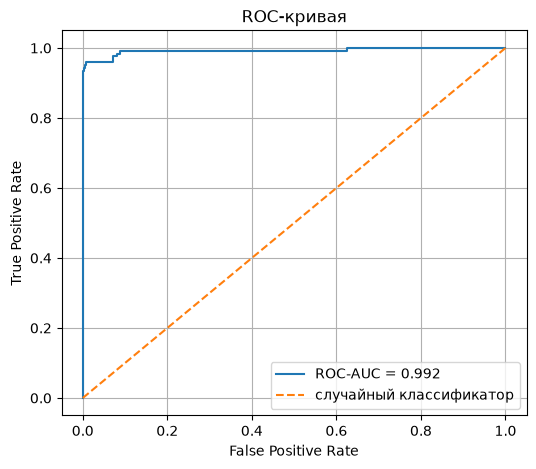

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Подставьте имя модели, которую вы обучили в предыдущей ячейке.
model_for_roc = model  # подставьте model

# 2. Укажите положительный класс.
positive_label = 1 # укажите метку положительного класса (спам)

# predict_proba возвращает вероятности для каждого класса.
# Найдём номер столбца, соответствующий положительному классу.
positive_class_index = list(model_for_roc.classes_).index(positive_label)
y_score = model_for_roc.predict_proba(X_test)[:, positive_class_index]

# roc_curve сравнивает истинные метки с оценками уверенности модели.
fpr, tpr, thresholds = roc_curve(y_test, y_score, pos_label=positive_label)

# Для ROC-AUC переведём истинные метки в 0/1:
# 1 — положительный класс, 0 — все остальные.
y_test_binary = (y_test == positive_label).astype(int)
roc_auc = roc_auc_score(y_test_binary, y_score)

# Сам график. Здесь можно поэкспериментировать с подписями и размером рисунка.
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая")
plt.legend()
plt.grid()
plt.show()


## Задание 5

### Подбор параметра `alpha`

Разберём простой способ подбора параметра модели **без кросс-валидации**. Для этого используем уже знакомый `train_test_split` и выделим из обучающей выборки отдельную валидационную часть.

**Важно:** при подборе `alpha` не используйте тестовую выборку. В задании 4 она уже использовалась для оценки базовой модели с `alpha=0.01`; теперь значения `alpha` сравниваем только на валидационной выборке.

1. Из уже имеющейся обучающей части `X_train_text, y_train` выделите 20% под валидацию (`test_size=0.2`, `stratify=y_train`, `random_state=42`).
2. Создайте **отдельный** `CountVectorizer` и обучите его только на внутренней обучающей части.
3. Проверьте несколько значений `alpha`, например `0.001, 0.01, 0.1, 1, 10`.
4. Для каждого значения посчитайте `F1` для положительного класса — **спам (`label=1`)** — на валидационной выборке.
5. Выберите значение `alpha` по валидационной выборке и кратко сформулируйте вывод: заметно ли качество зависит от `alpha`?
6. После выбора `alpha` переобучите модель на **всей исходной обучающей выборке** и снова оцените её на тестовой выборке, чтобы сравнить результат с базовой моделью из задания 4.


In [25]:
from sklearn.metrics import f1_score

# Ещё раз используем знакомый train_test_split,
# но теперь делим только исходную обучающую часть на train/validation.
X_train_inner_text, X_val_text, y_train_inner, y_val = train_test_split(
    X_train_text,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42,
)

# Для честной проверки словарь строим только по внутренней обучающей части.
vectorizer_val = CountVectorizer()
X_train_inner = vectorizer_val.fit_transform(X_train_inner_text)
X_val = vectorizer_val.transform(X_val_text)

alphas = [0.001, 0.01, 0.1, 1, 10]
results = []

for alpha in alphas:
    # 1. Создайте MultinomialNB с текущим alpha и обучите его.
    model_alpha = ...

    # 2. Получите предсказания на X_val.
    y_val_pred = ...

    # 3. Посчитайте F1 для положительного класса (спам, label=1).
    f1 = ...

    results.append((alpha, f1))

results


[(0.001, Ellipsis),
 (0.01, Ellipsis),
 (0.1, Ellipsis),
 (1, Ellipsis),
 (10, Ellipsis)]

**Промежуточная проверка:** проверяем, что результат получен для каждого значения `alpha`.

In [26]:
if len(results) == len(alphas):
    print("Все значения alpha проверены")
else:
    print("Проверьте цикл: результаты получены не для всех значений alpha")


Все значения alpha проверены


После сравнения значений `alpha` выберите одно значение по валидационной выборке.
Теперь переобучите модель на всей исходной обучающей выборке `X_train, y_train` и оцените её на `X_test, y_test`.

На этом этапе **не подбирайте `alpha` повторно по тестовым данным**: используйте уже выбранное по валидационной выборке значение. Сравните итоговые метрики с базовой моделью из задания 4 и кратко сформулируйте вывод.

In [27]:
best_alpha = ...  # выбранное по валидационной выборке значение

final_model = MultinomialNB(alpha=best_alpha)
final_model.fit(X_train, y_train)

y_test_pred_final = final_model.predict(X_test)

# Посчитайте здесь те же метрики, которые использовали в задании 4.
# ваш код здесь


InvalidParameterError: The 'alpha' parameter of MultinomialNB must be a float in the range [0.0, inf) or an array-like. Got Ellipsis instead.